In [ ]:

import os
import random
import string
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, ImageDraw, ImageFont

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASSES = string.digits + string.ascii_uppercase
IMG_SIZE = 32

print("TensorFlow :", tf.__version__)
print("Nombre de classes :", len(CLASSES))
print("Classes :", CLASSES)
print("GPU :", tf.config.list_physical_devices("GPU"))


TensorFlow : 2.21.0
Nombre de classes : 36
Classes : 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ
GPU : []


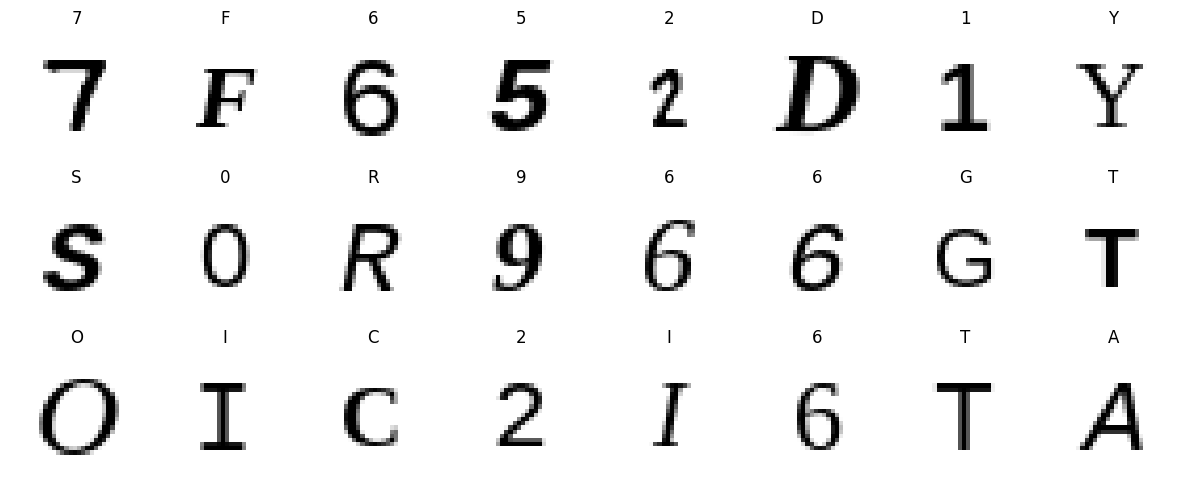

In [ ]:

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

font_paths = list(Path("/usr/share/fonts/truetype").rglob("*.ttf"))

if not font_paths:
    raise RuntimeError("Aucune police TrueType trouvée.")

def generate_character(char):
    image = Image.new("L", (32, 32), 255)
    draw = ImageDraw.Draw(image)

    font_path = random.choice(font_paths)
    font = ImageFont.truetype(str(font_path), random.randint(20, 28))

    bbox = draw.textbbox((0, 0), char, font=font)
    w = bbox[2] - bbox[0]
    h = bbox[3] - bbox[1]

    x = (32 - w) // 2 - bbox[0]
    y = (32 - h) // 2 - bbox[1]

    draw.text((x, y), char, fill=0, font=font)
    return np.array(image)

fig, axes = plt.subplots(3, 8, figsize=(12, 5))

for ax in axes.flat:
    char = random.choice(CLASSES)
    image = generate_character(char)
    ax.imshow(image, cmap="gray")
    ax.set_title(char)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from PIL import Image, ImageDraw, ImageFont, ImageFilter
from pathlib import Path
import numpy as np
import random

SAMPLES_PER_CLASS = 500

# Garder les polices classiques, sans italique
fonts = [
    p for p in Path("/usr/share/fonts/truetype").rglob("*.ttf")
    if not any(
        word in p.name.lower()
        for word in ["italic", "oblique", "script", "symbol"]
    )
]

print("Polices disponibles :", len(fonts))

if len(fonts) < 3:
    raise RuntimeError("Pas assez de polices disponibles.")

def create_sample(char, font_path):
    image = Image.new("L", (48, 48), 255)
    draw = ImageDraw.Draw(image)

    font = ImageFont.truetype(
        str(font_path),
        random.randint(25, 36)
    )

    bbox = draw.textbbox((0, 0), char, font=font)

    x = (48 - (bbox[2] - bbox[0])) / 2 - bbox[0]
    y = (48 - (bbox[3] - bbox[1])) / 2 - bbox[1]

    x += random.randint(-3, 3)
    y += random.randint(-3, 3)

    draw.text((x, y), char, font=font, fill=0)

    image = image.rotate(
        random.uniform(-8, 8),
        fillcolor=255
    )

    image = image.resize((32, 32))

    if random.random() < 0.2:
        image = image.filter(
            ImageFilter.GaussianBlur(radius=0.4)
        )

    return np.array(image, dtype=np.uint8)

X = []
y = []
font_ids = []

for label, char in enumerate(CLASSES):
    for _ in range(SAMPLES_PER_CLASS):
        font_id = random.randrange(len(fonts))
        img = create_sample(char, fonts[font_id])

        X.append(img)
        y.append(label)
        font_ids.append(font_id)

X = np.array(X)
y = np.array(y)
font_ids = np.array(font_ids)

print("Dataset :", X.shape)
print("Labels :", y.shape)
print("Mémoire :", round(X.nbytes / 1024**2, 2), "MB")


Polices disponibles : 7
Dataset : (18000, 32, 32)
Labels : (18000,)
Mémoire : 17.58 MB


In [ ]:

from sklearn.model_selection import train_test_split

unique_fonts = np.unique(font_ids)

train_fonts, temp_fonts = train_test_split(
    unique_fonts,
    test_size=0.30,
    random_state=42
)

val_fonts, test_fonts = train_test_split(
    temp_fonts,
    test_size=0.50,
    random_state=42
)

train_mask = np.isin(font_ids, train_fonts)
val_mask = np.isin(font_ids, val_fonts)
test_mask = np.isin(font_ids, test_fonts)

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

# Normalisation des pixels entre 0 et 1
# Inversion : caractère clair sur fond sombre
def preprocess(images):
    images = 1.0 - images.astype("float32") / 255.0
    return images[..., np.newaxis]

X_train = preprocess(X_train)
X_val = preprocess(X_val)
X_test = preprocess(X_test)

print("Train :", X_train.shape)
print("Validation :", X_val.shape)
print("Test :", X_test.shape)

print("Classes train :", len(np.unique(y_train)))
print("Classes validation :", len(np.unique(y_val)))
print("Classes test :", len(np.unique(y_test)))


Train : (10264, 32, 32, 1)
Validation : (2548, 32, 32, 1)
Test : (5188, 32, 32, 1)
Classes train : 36
Classes validation : 36
Classes test : 36


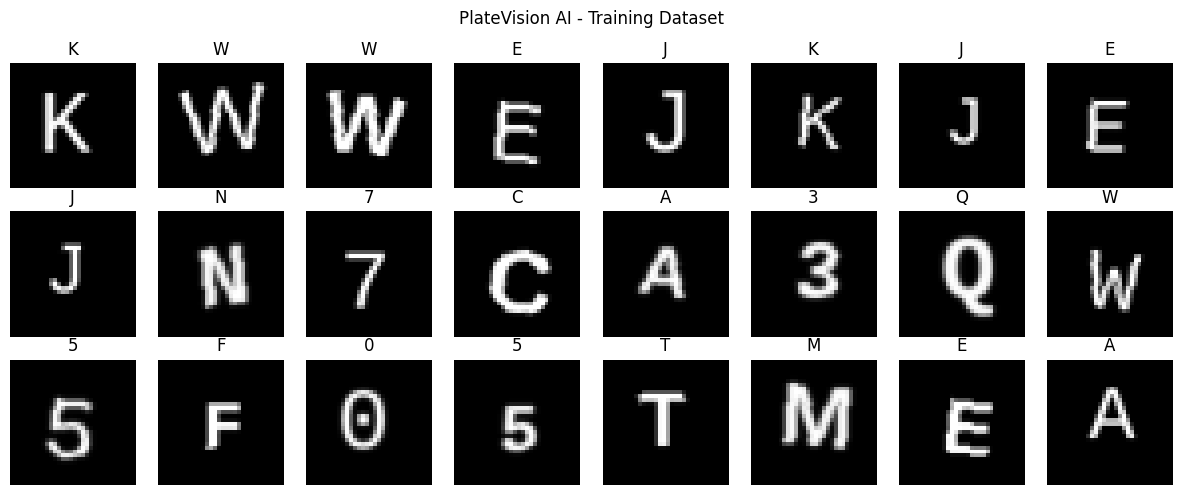

In [ ]:

fig, axes = plt.subplots(3, 8, figsize=(12, 5))

for ax in axes.flat:
    idx = random.randrange(len(X_train))

    ax.imshow(
        X_train[idx].squeeze(),
        cmap="gray"
    )
    ax.set_title(CLASSES[y_train[idx]])
    ax.axis("off")

plt.suptitle("PlateVision AI - Training Dataset")
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np

for name, images, labels in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(name, images.shape)
    print("Classes :", len(np.unique(labels)))
    print("Pixels :", images.min(), images.max())
    assert len(np.unique(labels)) == 36
    assert images.shape[1:] == (32, 32, 1)

assert not (set(train_fonts) & set(val_fonts))
assert not (set(train_fonts) & set(test_fonts))
assert not (set(val_fonts) & set(test_fonts))

print("Vérifications réussies !")


Train (10264, 32, 32, 1)
Classes : 36
Pixels : 0.0 1.0
Validation (2548, 32, 32, 1)
Classes : 36
Pixels : 0.0 1.0
Test (5188, 32, 32, 1)
Classes : 36
Pixels : 0.0 1.0
Vérifications réussies !


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(32, 32, 1)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(36, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,828 (444.64 KB)

 Trainable params: 113,828 (444.64 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "platevision_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 27s 157ms/step - accuracy: 0.0580 - loss: 3.3901 - val_accuracy: 0.1224 - val_loss: 3.1051
Epoch 2/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 39s 144ms/step - accuracy: 0.3433 - loss: 2.0466 - val_accuracy: 0.3195 - val_loss: 2.4565
Epoch 3/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 39s 131ms/step - accuracy: 0.6758 - loss: 0.9515 - val_accuracy: 0.3611 - val_loss: 2.2932
Epoch 4/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 42s 139ms/step - accuracy: 0.8190 - loss: 0.5354 - val_accuracy: 0.3709 - val_loss: 2.2971
Epoch 5/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 22s 139ms/step - accuracy: 0.8809 - loss: 0.3630 - val_accuracy: 0.4223 - val_loss: 2.1865
Epoch 6/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 141ms/step - accuracy: 0.9277 - loss: 0.2362 - val_accuracy: 0.4160 - val_loss: 2.3608
Epoch 7/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 23s 141ms/step - accuracy: 0.9387 - loss: 0.1939 - val_accuracy: 0.4502 - val_loss: 2.1103
Epoch 8/20
161/161 ━━━━━━━━━━━━━━━━━━━━ 41s 141ms/step - accuracy: 0.9544 - loss: 0

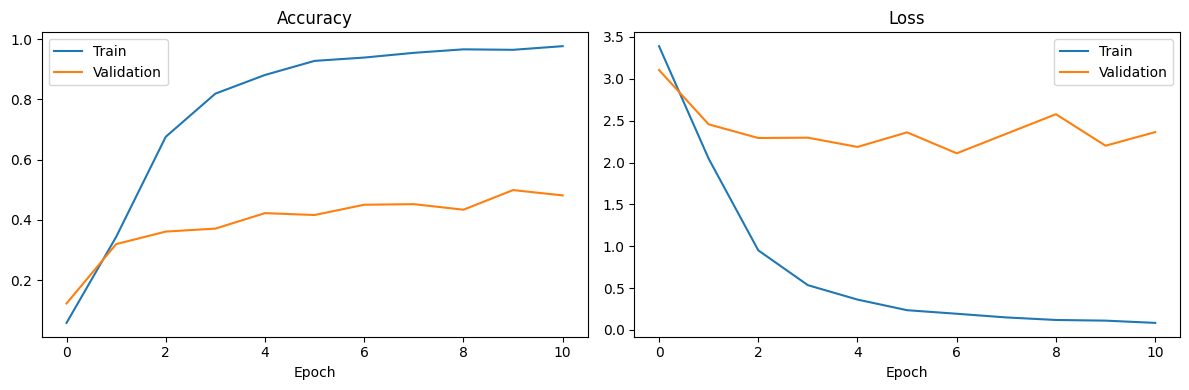

In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()


In [ ]:

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test accuracy : {test_accuracy:.2%}")
print(f"Test loss : {test_loss:.4f}")


Test accuracy : 57.36%
Test loss : 2.0567


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Charger le meilleur modèle enregistré
best_model = tf.keras.models.load_model(
    "platevision_cnn.keras"
)

# Prédictions sur le test
pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(pred_probs, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(CLASSES)),
    target_names=list(CLASSES),
    zero_division=0
))

# Identifier les confusions les plus fréquentes
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(CLASSES))
)

np.fill_diagonal(cm, 0)

confusions = []

for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j] > 0:
            confusions.append(
                (cm[i, j], CLASSES[i], CLASSES[j])
            )

confusions.sort(reverse=True)

print("\nTop 10 des confusions :")
for count, true_char, pred_char in confusions[:10]:
    print(
        f"{true_char} -> {pred_char} : {count} erreurs"
    )


              precision    recall  f1-score   support

           0       0.00      0.00      0.00       134
           1       0.43      0.35      0.38       142
           2       0.58      0.68      0.62       140
           3       0.62      0.33      0.43       132
           4       0.60      0.41      0.49       155
           5       0.93      0.51      0.66       147
           6       0.00      0.00      0.00       160
           7       0.60      1.00      0.75       152
           8       0.50      0.45      0.48       137
           9       0.85      0.46      0.60       157
           A       0.88      0.70      0.78       152
           B       0.99      0.71      0.83       135
           C       0.55      1.00      0.71       148
           D       0.57      0.92      0.70       132
           E       1.00      0.54      0.70       133
           F       0.86      0.51      0.64       154
           G       0.33      0.33      0.33       134
           H       0.44    

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.04),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.15)
], name="augmentation")

model_v2 = models.Sequential([
    layers.Input(shape=(32, 32, 1)),

    augmentation,

    layers.Conv2D(32, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(128, 3, padding="same", use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(36, activation="softmax")
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 8, 8, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,294,660 (4.94 MB)

 Trainable params: 1,293,956 (4.94 MB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:

callbacks_v2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "platevision_cnn_v2.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_v2 = model_v2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=callbacks_v2,
    verbose=1
)


Epoch 1/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 59s 329ms/step - accuracy: 0.1160 - loss: 3.1868 - val_accuracy: 0.0338 - val_loss: 3.8776 - learning_rate: 5.0000e-04
Epoch 2/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 53s 331ms/step - accuracy: 0.3416 - loss: 2.1638 - val_accuracy: 0.2578 - val_loss: 2.6459 - learning_rate: 5.0000e-04
Epoch 3/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 52s 321ms/step - accuracy: 0.5249 - loss: 1.4328 - val_accuracy: 0.6978 - val_loss: 1.1886 - learning_rate: 5.0000e-04
Epoch 4/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 82s 323ms/step - accuracy: 0.6295 - loss: 1.0708 - val_accuracy: 0.6766 - val_loss: 1.0148 - learning_rate: 5.0000e-04
Epoch 5/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 81s 315ms/step - accuracy: 0.6977 - loss: 0.8553 - val_accuracy: 0.7547 - val_loss: 0.6272 - learning_rate: 5.0000e-04
Epoch 6/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 317ms/step - accuracy: 0.7343 - loss: 0.7465 - val_accuracy: 0.6735 - val_loss: 1.0215 - learning_rate: 5.0000e-04
Epoch 7/30
161/161 ━━━━━━━━━━━━━━━━━━━━ 83s 32

Accuracy V1 : 57.36%
Accuracy V2 : 80.65%
Différence : +23.28 points


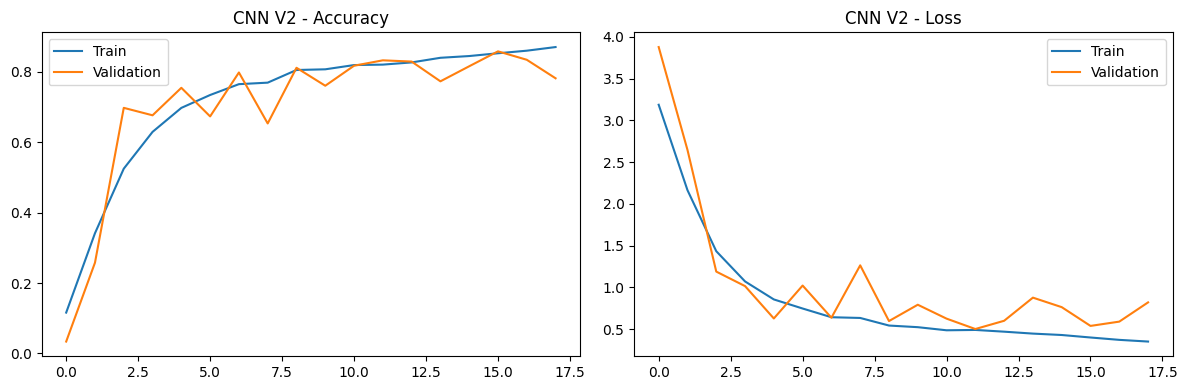

              precision    recall  f1-score   support

           0       0.64      0.89      0.75       134
           1       1.00      0.29      0.45       142
           2       0.95      1.00      0.97       140
           3       1.00      0.14      0.25       132
           4       0.93      0.42      0.58       155
           5       0.57      1.00      0.72       147
           6       0.55      0.99      0.71       160
           7       0.92      1.00      0.96       152
           8       0.92      0.97      0.94       137
           9       0.66      0.50      0.57       157
           A       0.99      0.93      0.96       152
           B       0.56      0.59      0.57       135
           C       0.99      1.00      1.00       148
           D       0.79      0.97      0.87       132
           E       1.00      0.81      0.90       133
           F       0.99      0.84      0.91       154
           G       0.86      0.98      0.91       134
           H       0.99    

In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

best_v1 = tf.keras.models.load_model(
    "platevision_cnn.keras"
)
best_v2 = tf.keras.models.load_model(
    "platevision_cnn_v2.keras"
)

# Comparaison sur le même ensemble de test
loss_v1, acc_v1 = best_v1.evaluate(
    X_test, y_test, verbose=0
)
loss_v2, acc_v2 = best_v2.evaluate(
    X_test, y_test, verbose=0
)

print(f"Accuracy V1 : {acc_v1:.2%}")
print(f"Accuracy V2 : {acc_v2:.2%}")
print(f"Différence : {(acc_v2-acc_v1)*100:+.2f} points")

# Courbes V2
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_v2.history["accuracy"],
    label="Train"
)
axes[0].plot(
    history_v2.history["val_accuracy"],
    label="Validation"
)
axes[0].set_title("CNN V2 - Accuracy")
axes[0].legend()

axes[1].plot(
    history_v2.history["loss"],
    label="Train"
)
axes[1].plot(
    history_v2.history["val_loss"],
    label="Validation"
)
axes[1].set_title("CNN V2 - Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("cnn_v2_training.png", dpi=150)
plt.show()

# Rapport V2
pred_v2 = np.argmax(
    best_v2.predict(X_test, verbose=0),
    axis=1
)

print(classification_report(
    y_test,
    pred_v2,
    labels=np.arange(36),
    target_names=list(CLASSES),
    zero_division=0
))


In [ ]:

import json
import tensorflow as tf
from google.colab import files

# Charger le meilleur checkpoint
best_model = tf.keras.models.load_model(
    "platevision_cnn_v2.keras"
)

# Sauvegarder les classes dans leur ordre exact
with open("classes.json", "w", encoding="utf-8") as f:
    json.dump(list(CLASSES), f, indent=2)

# Sauvegarder les métriques
results = {
    "model": "PlateVision CNN V2",
    "dataset": "Synthetic alphanumeric characters",
    "num_classes": len(CLASSES),
    "image_size": [32, 32],
    "test_samples": int(len(y_test)),
    "accuracy_v1": float(acc_v1),
    "accuracy_v2": float(acc_v2),
    "test_loss_v2": float(loss_v2),
    "limitations": [
        "Synthetic data only",
        "No real-world license plate evaluation yet"
    ]
}

with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)

# Télécharger les fichiers
for filename in [
    "platevision_cnn_v2.keras",
    "classes.json",
    "results.json",
    "cnn_v2_training.png"
]:
    files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>